In [1]:
import numpy as np
import cv2
from matplotlib import pyplot as plt
from segmentation import combined_segmentation
from get_colored_globe import merge_pcd_gnd_6th, get_colored_pcd, filter_globe, fit_spheroid, visualize_results

Merge point clouds from the ground and 6th floors

In [2]:
file_path_6th = '../points/6th_floor.pcd'
file_path_ground = '../points/ground.pcd'
combined_pcd_path    = '../points/combined_globe.pcd'

merge_pcd_gnd_6th(file_path_6th, file_path_ground, combined_pcd_path)

Loading ../points/6th_floor.pcd and ../points/ground.pcd...
Saving point cloud to ../points/combined_globe.pcd.
Total points: 600000


Assign RGB values to the point cloud from the image

In [3]:
image_path = '../globe_image/projection.png'
colored_pcd_path = '../points/colored_globe.pcd'

get_colored_pcd(combined_pcd_path, image_path, colored_pcd_path, visualise=True)

Projected 266261 valid points out of 600000.
Saving to ../points/colored_globe.pcd...


PointCloud with 600000 points.

Filter the AO points only

In [4]:
filtered_globe_path = '../points/filtered_globe.pcd'

filtered_globe_points, globe_pcd = filter_globe(colored_pcd_path, filtered_globe_path)

Globe point cloud with 129003 points.
Saving to ../points/filtered_globe.pcd...


Fit AO's point cloud to ellipsoid

In [5]:
result = fit_spheroid(filtered_globe_points)

# Ellipsoid centre (cx, cy, cz), Equatorial radius r_xy, Polar radius r_z

cx_e, cy_e, cz_e, r_xy_e, r_z_e = result.x

rmse = np.sqrt(np.mean(result.fun**2))

visualize_results(globe_pcd, (cx_e, cy_e, cz_e), r_xy_e, r_z_e)

print(f"Center: ({cx_e:.2f}, {cy_e:.2f}, {cz_e:.2f})")
print(f"XY Diameter: {2*r_xy_e:.2f}")
print(f"Z Diameter: {2*r_z_e:.2f}")
print(f"RMSE: {np.round(rmse, 4)} m")

Opening visualization window...
Center: (18.63, -2.50, -1.29)
XY Diameter: 8.42
Z Diameter: 7.95
RMSE: 0.0165 m


### Diameter Consistency Analysis


==== Q4(a) results for Easy 000002 ====
Visual based analysis
Polar diameter: 642.3 px  -> 7.972 m
Equatorial diameter: 678.3 px -> 8.420 m
Scale at the globe's XZ plane: 0.01241 m/px

Ellipsoid model
Polar diameter: 8.420 m
Equatorial diameter: 7.960 m


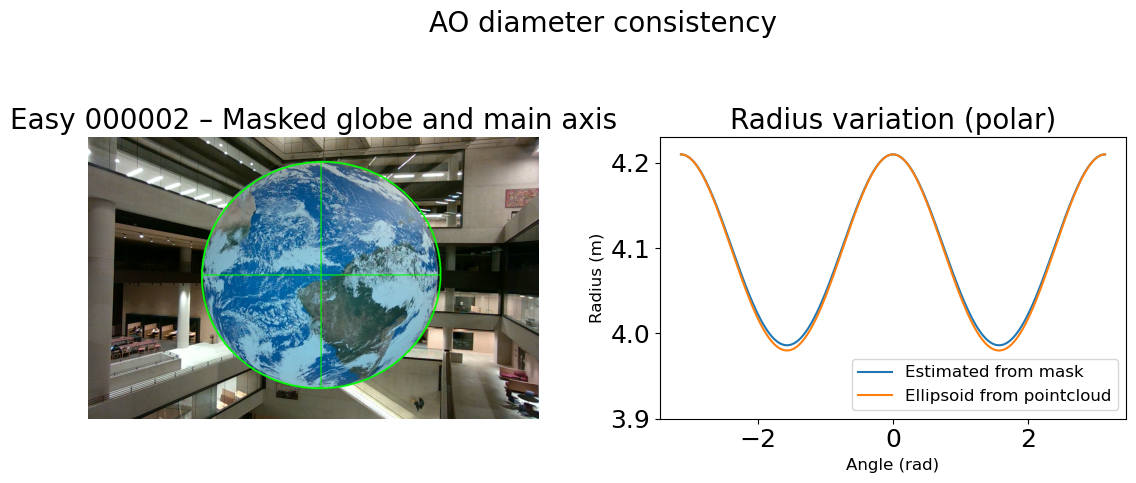

In [6]:
GLOBE_EQUATORIAL_R_M = np.round(r_xy_e, 2)
GLOBE_POLAR_R_M = np.round(r_z_e, 2)
title = "Easy 000002"

bgr_img = cv2.imread('../Dataset_25/Easy/images/000002.png')

def analyse_radius(mask, ax_polar=None):

    # Visual based analysis given the segmented AO from the image

    # Approximation of the mask to an ellipse
    m = mask > 0
    m_uint8 = (m.astype(np.uint8) * 255)

    contours, _ = cv2.findContours(m_uint8, cv2.RETR_EXTERNAL,
                                   cv2.CHAIN_APPROX_SIMPLE)
    if len(contours) == 0:
        return None

    cnt = max(contours, key=cv2.contourArea)
    if len(cnt) < 5: return None
    ellipse = cv2.fitEllipse(cnt)
    (cx, cy), (d1, d2), angle_deg = ellipse

    # Conversion from pixels to meters using the ellipsoid known equatorial diameter
    pixel_to_m = 2 * GLOBE_EQUATORIAL_R_M / d2
    angles_sorted = np.linspace(-np.pi, np.pi, 360)

    # Radius variation along the globe's XZ plane in the segmented mask
    radii_sorted = (d2/2 * d1/2) / np.sqrt((d1/2 * np.cos(angles_sorted))**2 + (d2/2 * np.sin(angles_sorted))**2)
    radii_sorted = pixel_to_m * radii_sorted

    # Radius variation of the ellipsoid model along the globe's XZ plane
    ellipse_radius = (GLOBE_EQUATORIAL_R_M * GLOBE_POLAR_R_M) / np.sqrt((GLOBE_POLAR_R_M * np.cos(angles_sorted))**2 + (GLOBE_EQUATORIAL_R_M * np.sin(angles_sorted))**2)

    if ax_polar is not None:

        # Plot for the radius variation
        ax_polar.plot(angles_sorted, radii_sorted, label='Estimated from mask')
        ax_polar.plot(angles_sorted, ellipse_radius, label='Ellipsoid from pointcloud')
        ax_polar.set_title("Radius variation (polar)")
        ax_polar.set_xlabel("Angle (rad)")
        ax_polar.set_ylabel("Radius (m)")
        ax_polar.legend(fontsize=12, loc='lower right')
        ax_polar.set_ylim(3.9, 4.23)

    return ellipse, pixel_to_m

context_settings = {
    'font.size': 18,
    'axes.titlesize': 20,
    'axes.labelsize': 12
}

with plt.rc_context(context_settings):

    fig, axes = plt.subplots(1, 2, figsize=(11, 5))
    fig.suptitle("AO diameter consistency", fontsize=20)
    fig.subplots_adjust(wspace=0.3, hspace=0.3)

    rgb_img = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2RGB)

    # Get the AO mask
    overlay_comb, comb_mask, ws_mask, rg_mask, km_mask = combined_segmentation(bgr_img.copy())
    overlay_with_lines = overlay_comb.copy()
    ellipse, pixel_to_m = analyse_radius(comb_mask, ax_polar=axes[1])

    (cx, cy), (d1, d2), angle_deg = ellipse

    left = int(cx - d2 / 2)
    right = int(cx + d2 / 2)
    top = int(cy - d1 / 2)
    bottom = int(cy + d1 / 2) 

    cv2.line(overlay_with_lines, (left,  np.int32(cy)), (right, np.int32(cy)), (0, 255, 0), 2)     
    cv2.line(overlay_with_lines, (np.int32(cx), top), (np.int32(cx), bottom), (0, 255, 0), 2)      
    cv2.ellipse(overlay_with_lines, ellipse, (0, 255, 0), 4)              

    axes[0].imshow(overlay_with_lines)
    axes[0].set_title(f"{title} – Masked globe and main axis")
    axes[0].axis("off")

    print(f"\n==== Q4(a) results for {title} ====\nVisual based analysis")
    print(f"Polar diameter: {d1:.1f} px  -> {d1*pixel_to_m:.3f} m")
    print(f"Equatorial diameter: {d2:.1f} px -> {d2*pixel_to_m:.3f} m")
    print(f"Scale at the globe's XZ plane: {pixel_to_m:.5f} m/px")
    print(f"\nEllipsoid model")
    print(f"Polar diameter: {2*GLOBE_EQUATORIAL_R_M:.3f} m")
    print(f"Equatorial diameter: {2*GLOBE_POLAR_R_M:.3f} m")

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

## Calculate surface linear velocity

We use the angular velocity estimation in real time from task 3e

Additions to the code are marked with """ TASK 4b """

Video Loaded: Resolution 1280x720 | FPS: 30.00 | Delta_t: 0.0333s
Geometry Initialized: Center (np.uint16(676), np.uint16(348)), Radius 199
Detected 81 initial features within the restricted equatorial band.
Initialization complete. Found 81 features for KLT tracking.
Mean linear velocity: 0.064 at 37.4 N
Mean linear velocity: 0.077 at 20.5 N
Mean linear velocity: 0.082 at 7.0 N
Mean linear velocity: 0.081 at 5.9 S
Mean linear velocity: 0.077 at 19.9 S


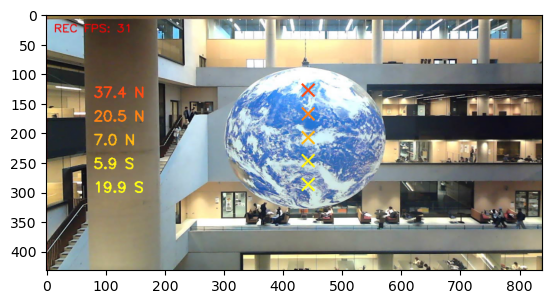

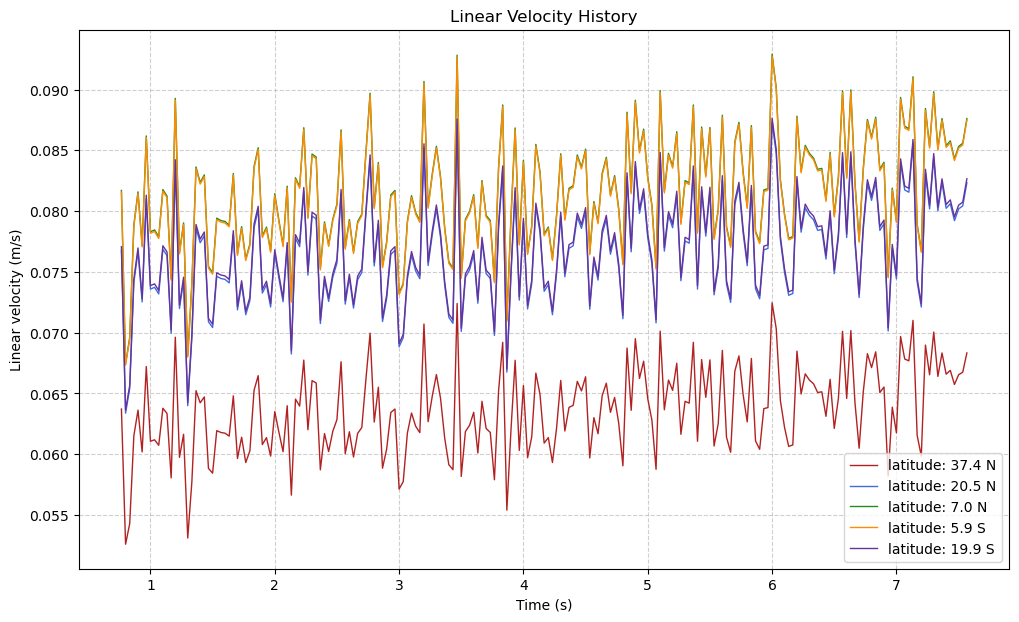

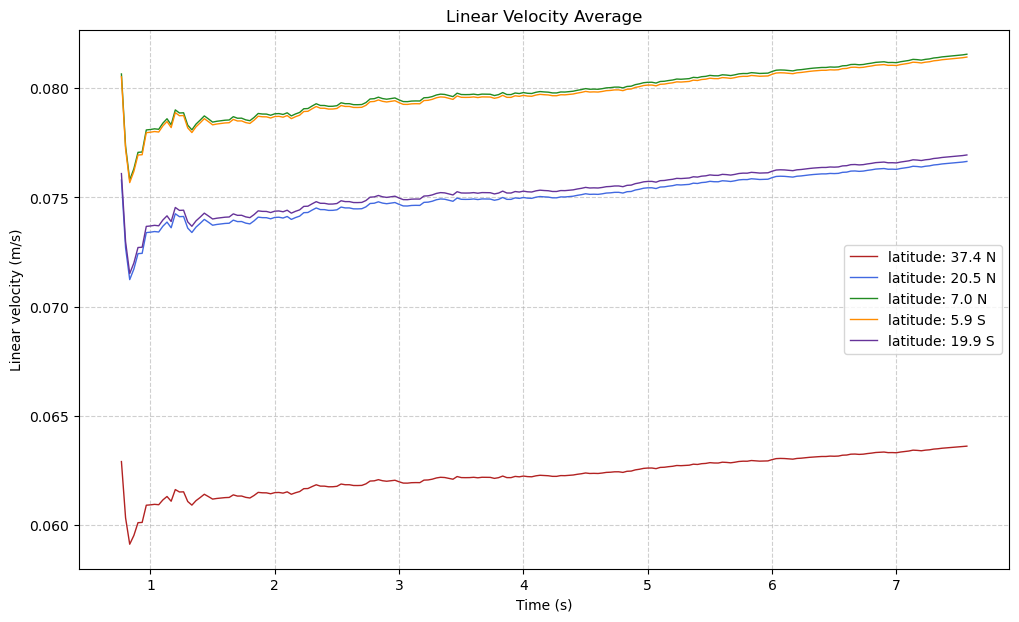

In [10]:
""" Optical Flow Side View with fixed window and plotting"""
import cv2
import numpy as np
import time
import math
import matplotlib.pyplot as plt
from get_point_radius_lat import get_latitude_radius

# --- Configuration ---
VIDEO_PATH = "../globe_image/ground_floor_rotation_video.avi" 
START_FRAME_INDEX = 20 

# KLT Feature Detection (Initial Phase)
MAX_FEATURES = 250
FEATURE_QUALITY_LEVEL = 0.001
FEATURE_MIN_DISTANCE = 10
RE_TRACK_MIN_COUNT = 50 

# KLT Optical Flow Parameters
LK_WINDOW_SIZE = (21, 21) 
LK_MAX_LEVEL = 3
LK_CRITERIA = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 10, 0.03)

# Equatorial Tracking Parameters 
EQUATORIAL_BAND_HEIGHT_RATIO = 0.20 
EQUATORIAL_BAND_WIDTH_RATIO = 0.80 # Restricts tracking to the central 80% of the globe width

# Hough Circle parameters (Geometry setup)
HOUGH_DP = 1 
HOUGH_MIN_DIST = 100 
HOUGH_PARAM1 = 50 
HOUGH_PARAM2 = 30 

# --- Global Plotting State Variables ---
time_history = []
velocity_history = []
average_history = []


# --- State Variables ---
globe_center = None
globe_radius = None
fps = 0
frame_counter = 0

# KLT Tracking State
prev_points = None 
prev_gray = None 
EXPECTED_CYCLE = 367.17

""" TASK 4b """

# Linear velocity calculation
globe_pcd_path = '../points/filtered_globe.pcd'
N_TARGETS = 5
CENTRE_OF_ROTATION = (cx_e, cy_e, cz_e)


def find_globe_geometry(frame):
    """
    Finds the center and radius of the globe.
    """
    if frame is None:
        return None, None
        
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (9, 9), 2)
    
    min_rad = int(frame.shape[0]*0.15)
    max_rad = int(frame.shape[0]*0.4)
    
    circles = cv2.HoughCircles(blurred, cv2.HOUGH_GRADIENT, HOUGH_DP, HOUGH_MIN_DIST,
                               param1=HOUGH_PARAM1, param2=HOUGH_PARAM2, 
                               minRadius=min_rad, maxRadius=max_rad)

    if circles is not None:
        circles = np.uint16(np.around(circles))
        best_circle = circles[0, 0]
        center = (best_circle[0], best_circle[1])
        radius = best_circle[2]
        
        print(f"Geometry Initialized: Center {center}, Radius {radius}")
        return center, radius
    else:
        print("Warning: Hough Circle failed to detect the globe.")
        return None, None


def detect_initial_features_in_band(frame_gray, center, radius):
    """
    Detects strong corners and restricts them to the restricted equatorial band using a mask.
    """
    mask = np.zeros_like(frame_gray)
    cx, cy = center
    
    # Define the horizontal equatorial band (ROI) height
    half_band_height = int(radius * EQUATORIAL_BAND_HEIGHT_RATIO / 2)
    
    # Define the horizontal equatorial band (ROI) width
    restricted_radius = int(radius * EQUATORIAL_BAND_WIDTH_RATIO)
    
    # Define rectangle coordinates: top-left (x, y) and bottom-right (x, y)
    rect_top_left = (cx - restricted_radius, cy - half_band_height)
    rect_bottom_right = (cx + restricted_radius, cy + half_band_height)
    
    # Create the rectangular mask
    cv2.rectangle(mask, rect_top_left, rect_bottom_right, 255, -1) 
    
    points = cv2.goodFeaturesToTrack(frame_gray, 
                                     maxCorners=MAX_FEATURES, 
                                     qualityLevel=FEATURE_QUALITY_LEVEL, 
                                     minDistance=FEATURE_MIN_DISTANCE,
                                     mask=mask)

    if points is None or len(points) < RE_TRACK_MIN_COUNT:
        return None
        
    print(f"Detected {len(points)} initial features within the restricted equatorial band.")
    return points


def calculate_angular_velocity(p0, p1, center, radius, delta_t):
    """
    Calculates the rotation cycle based on the median horizontal displacement (Delta X).
    """
    if not p0.size or not p1.size or len(p0) != len(p1) or len(p0) < 5:
        return None

    p0_reshaped = p0.reshape(-1, 2)
    p1_reshaped = p1.reshape(-1, 2)

    delta_x = p1_reshaped[:, 0] - p0_reshaped[:, 0]
    median_delta_x = np.median(delta_x)
    
    if radius == 0:
        return None
        
    omega = abs(median_delta_x / delta_t / radius)
    
    if omega < 1e-6: 
        return None
        
    rotation_cycle = 2 * math.pi / omega
    
    return rotation_cycle


def apply_geometric_filter(p_old, p_new, center, radius):
    """
    Filters tracked points to ensure they remain within the restricted equatorial tracking band.
    """
    cx, cy = center
    half_band_height = int(radius * EQUATORIAL_BAND_HEIGHT_RATIO / 2)
    restricted_radius = int(radius * EQUATORIAL_BAND_WIDTH_RATIO)
    
    min_y = cy - half_band_height
    max_y = cy + half_band_height
    
    min_x = cx - restricted_radius 
    max_x = cx + restricted_radius 

    p_new_flat = p_new.reshape(-1, 2)
    
    is_in_band_y = (p_new_flat[:, 1] >= min_y) & (p_new_flat[:, 1] <= max_y)
    is_in_band_x = (p_new_flat[:, 0] >= min_x) & (p_new_flat[:, 0] <= max_x)
    
    is_in_band = is_in_band_x & is_in_band_y
    
    filtered_p_new = p_new[is_in_band]
    filtered_p_old = p_old[is_in_band]
    
    return filtered_p_old, filtered_p_new


def plot_results_after_processing(latitudes):
    """
    [NEW FUNCTION] Creates and displays the final, non-interactive plot of the collected data.
    """
    global time_history, velocity_history, average_history, EXPECTED_CYCLE
    
    if not time_history:
        print("No velocity data was collected to plot.")
        return
    
    colours = ['firebrick', 'royalblue', 'forestgreen', 'darkorange', 'rebeccapurple', 'gold']

    plt.figure(figsize=(12, 7))
    plt.title("Linear Velocity History")
    plt.xlabel("Time (s)")
    plt.ylabel("Linear velocity (m/s)")
    plt.grid(True, linestyle='--', alpha=0.6)

    history_matrix = np.array(velocity_history)
    history_matrix_1 = history_matrix[2:, :]

    time_history_1 = time_history[2:]

    # 2. Iterate over the COLUMNS (0 to 5), not the rows
    num_latitudes = history_matrix_1.shape[1]

    for i in range(num_latitudes):

        vel_column = history_matrix_1[:, i]
    
        # Plotting running average
        if latitudes[i] > 0: latitude_text = latitudes[i].copy(); latitude_hemisphere = 'N'
        else: latitude_text = latitudes[i].copy() * -1; latitude_hemisphere = 'S'

        print(f"Mean linear velocity: {np.round(np.mean(vel_column), 3)} at {latitude_text} {latitude_hemisphere}")

        plt.plot(time_history_1, vel_column, '-', label=f'latitude: {latitude_text} {latitude_hemisphere}', linewidth=1, color=colours[i])
        plt.legend()

    plt.show()

def plot_average(latitudes):
    """
    [NEW FUNCTION] Creates and displays the final, non-interactive plot of the collected data.
    """
    global time_history, velocity_history, average_history, EXPECTED_CYCLE
    
    if not time_history:
        print("No velocity data was collected to plot.")
        return
    
    colours = ['firebrick', 'royalblue', 'forestgreen', 'darkorange', 'rebeccapurple', 'gold']

    plt.figure(figsize=(12, 7))
    plt.title("Linear Velocity Average")
    plt.xlabel("Time (s)")
    plt.ylabel("Linear velocity (m/s)")
    plt.grid(True, linestyle='--', alpha=0.6)

    history_matrix = np.array(average_history)
    history_matrix_1 = history_matrix[2:, :]

    time_history_1 = time_history[2:]

    # 2. Iterate over the COLUMNS (0 to 5), not the rows
    num_latitudes = history_matrix_1.shape[1]

    for i in range(num_latitudes):

        vel_column = history_matrix_1[:, i]
    
        # Plotting running average
        if latitudes[i] > 0: latitude_text = latitudes[i].copy(); latitude_hemisphere = 'N'
        else: latitude_text = latitudes[i].copy() * -1; latitude_hemisphere = 'S'

        plt.plot(time_history_1, vel_column, '-', label=f'latitude: {latitude_text} {latitude_hemisphere}', linewidth=1, color=colours[i])
        plt.legend()

    plt.show()

""" TASK 4b """

def calculate_linear_vel(cycle_estimate, latitude_radius):
    
    return 2 * np.pi * latitude_radius / cycle_estimate

def process_live_video():
    """
    The main loop for KLT tracking and velocity estimation.
    """
    global globe_center, globe_radius, fps, frame_counter, prev_points, prev_gray
    global time_history, velocity_history, average_history

    cap = cv2.VideoCapture(VIDEO_PATH)
    if not cap.isOpened():
        print(f"Error: Could not open video file at {VIDEO_PATH}")
        return

    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    frame_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))  
    
    if fps == 0:
        print("Error: Could not determine video FPS.")
        cap.release()
        return

    delta_t = 1.0 / fps
    print(f"Video Loaded: Resolution {frame_width}x{frame_height} | FPS: {fps:.2f} | Delta_t: {delta_t:.4f}s")
    
    
    # --- Initialization Phase (No change) ---
    while frame_counter < START_FRAME_INDEX:
        ret, frame = cap.read()
        if not ret: break
        frame_counter += 1

    if frame is None:
        print("Exiting: Failed to reach start frame.")
        cap.release()
        return

    globe_center, globe_radius = find_globe_geometry(frame)
    if globe_center is None: 
        cap.release()
        return
    
    prev_gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    prev_points = detect_initial_features_in_band(prev_gray, globe_center, globe_radius)

    if prev_points is None:
        print("Error: Initial feature detection failed.")
        cap.release()
        return
    
    """ TASK 4b """
    # Calculate the latitude and radius of rotation for the input points in the globe's surfarface retrieved from the image
    
    latitude_radius, original_target_points, latitudes, rgb = get_latitude_radius(frame, globe_pcd_path, CENTRE_OF_ROTATION, globe_center, globe_radius, N_TARGETS)

    target_points = original_target_points[1:-1]

    plt.imshow(rgb)
    
    print(f"Initialization complete. Found {len(prev_points)} features for KLT tracking.")  
    
    # --- Real-Time Tracking Loop ---
    rotation_cycle_smoothed = None

    refresh_text = 0

    latitude_vel_text = [0.0] * 6

    normalized_vel = 0

    vel_plot = [0] * 6
    
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            print("End of video stream.")
            break
            
        refresh_text += 1

        frame_counter += 1
        start_time = time.time()
        current_gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        
        # --- 1. KLT Tracking & 2. Geometric Band Filter (Filtering remains the same) ---
        current_points, status, err = cv2.calcOpticalFlowPyrLK(
            prev_gray, current_gray, prev_points, None, winSize=LK_WINDOW_SIZE, 
            maxLevel=LK_MAX_LEVEL, criteria=LK_CRITERIA
        )
        
        good_old = prev_points[status == 1]
        good_new = current_points[status == 1]
        
        if good_new.size > 0:
            good_old, good_new = apply_geometric_filter(good_old, good_new, globe_center, globe_radius)
        
        final_inlier_count = len(good_new)
        
        # --- 3. Re-initialization Check (Remains the same) ---
        re_detect_needed = (final_inlier_count < RE_TRACK_MIN_COUNT)

        if re_detect_needed:
            new_points = detect_initial_features_in_band(current_gray, globe_center, globe_radius)
            if new_points is not None and len(new_points) >= RE_TRACK_MIN_COUNT:
                prev_points = new_points
            else:
                prev_points = good_new.reshape(-1, 1, 2) if good_new.size > 0 else np.array([])
        else:
             prev_points = good_new.reshape(-1, 1, 2)
        
        prev_gray = current_gray.copy() 
        
        # --- 4. Angular Velocity Calculation & Data Collection ---
        current_time_sec = frame_counter * delta_t
        cycle_estimate = None

        if good_old.size > 0 and good_new.size > 0 and len(good_new) >= 5: 
            cycle_estimate = calculate_angular_velocity(good_old, good_new, globe_center, globe_radius, delta_t)
            
            if cycle_estimate is not None:

                """ TASK 4b """
                linear_velocities = calculate_linear_vel(cycle_estimate, latitude_radius)

                # Data Collection (No longer updating an interactive plot)
                time_history.append(current_time_sec)
                velocity_history.append(linear_velocities)
                current_avg = np.mean(velocity_history, axis=0)
                average_history.append(current_avg)
                
                # Smoothed display (for video HUD)
                if rotation_cycle_smoothed is None:
                    rotation_cycle_smoothed = cycle_estimate
                else:
                    rotation_cycle_smoothed = 0.9 * rotation_cycle_smoothed + 0.1 * cycle_estimate 
            
        # --- 5. Visualization (OpenCV HUD only) ---
        
        processing_time = time.time() - start_time
        
        cycle_display = "N/A"
        if rotation_cycle_smoothed is not None:
            cycle_display = f"Smoothed Cycle: {rotation_cycle_smoothed:.2f} s/rot"
                 
            cv2.putText(frame, cycle_display, (frame_width - 320, 30), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)
                
        cv2.putText(frame, f"Time: {current_time_sec:.2f}s", (30, 80), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 0), 2)
        cv2.putText(frame, f"Active Tracks: {final_inlier_count}", (30, 120), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 100, 255), 2)

        speed_check = f"Proc Time: {processing_time*1000:.2f} ms | FPS Target: {delta_t*1000:.2f} ms"
        cv2.putText(frame, speed_check, (10, frame_height - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 255), 1)

        # Draw the active features
        for point in good_new:
            x, y = point.ravel().astype(int)
            frame = cv2.circle(frame, (x, y), 3, (0, 255, 255), -1)

        # Draw the restricted tracking band boundaries (Rectangle)
        half_band_height = int(globe_radius * EQUATORIAL_BAND_HEIGHT_RATIO / 2)
        restricted_radius = int(globe_radius * EQUATORIAL_BAND_WIDTH_RATIO)
        cx, cy = globe_center
        rect_top_left = (cx - restricted_radius, cy - half_band_height)
        rect_bottom_right = (cx + restricted_radius, cy + half_band_height)
        cv2.rectangle(frame, rect_top_left, rect_bottom_right, (0, 165, 255), 1)

        text_height = 180

        text_colour = np.array([20, 20, 255])
        colour_tuple = text_colour.tolist()

        """ TASK 4b """
        
        # Put the instantaneous linear velocity and indicativa arrows at the target points in the frame
        cv2.putText(frame, f"Linear velocities:", (100, text_height), cv2.FONT_HERSHEY_SIMPLEX, 0.8, colour_tuple, 2)

        for i, latitude_vel in enumerate(linear_velocities):

            text_height += 65
            text_colour[1] += 55
            colour_tuple = text_colour.tolist()

            if refresh_text == 15:

                latitude_vel_text[i] = latitude_vel
                normalized_vel = latitude_vel / 0.08
                vel_plot[i] = int(100 * normalized_vel)

            if latitudes[i] > 0: latitude_text = latitudes[i].copy(); latitude_hemisphere = 'N'
            else: latitude_text = latitudes[i].copy() * -1; latitude_hemisphere = 'S'    

            cv2.arrowedLine(frame, (globe_center[0], target_points[i]), (globe_center[0] + vel_plot[i], target_points[i]), colour_tuple, 2)
            cv2.putText(frame, f"At {latitude_text} {latitude_hemisphere}: {np.round(latitude_vel_text[i], 4)} m/s", (100, text_height), cv2.FONT_HERSHEY_SIMPLEX, 0.8, colour_tuple, 2)

        if refresh_text == 15: refresh_text = 0

        cv2.imshow('KLT Optical Flow Tracker (Equatorial View)', frame)
        
        if cv2.waitKey(1) & 0xFF == ord('q'):
            break

    cap.release()
    cv2.destroyAllWindows()
    
    # --- Final Step: Generate Plot ---
    plot_results_after_processing(latitudes)
    plot_average(latitudes)


if __name__ == "__main__":
    plt.ioff()
    process_live_video()